# Неделя 13 — Итоговый notebook и защита

Цель: объединить материалы, таблицу прогресса и презентацию на 10 слайдов. Личную защиту проводит автор проекта; данный notebook содержит демонстрацию и структуру доклада.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'nlp_project').exists() else Path.cwd().parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import json
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown
from nlp_project.core import corpus, clean, tokens, metrics, SEED
df = corpus()
train, val, test = [df[df.split == s].copy() for s in ('train', 'validation', 'test')]


# Анализ тональности отзывов о товарах маркетплейса

## Статус и постановка задачи

Python-проект: бинарная классификация тональности реальных английских отзывов о телефонах и аксессуарах Amazon. Интерфейс и учебные материалы на русском. Расписание: недели 1–6, затем 8–13; неделя 7 пропущена по заданию.

**Блокер недель 8–11:** сеть запрещает huggingface.co (HTTP 403). Код реализован, но pretrained BERT, attention и fine-tuning ещё не выполнены. Метрики BERT отсутствуют, случайная модель не подставлялась.

## Данные и протокол

Источник: UCI Sentiment Labelled Sentences, Kotzias et al. (KDD 2015), DOI: https://doi.org/10.24432/C57604. Только файл Amazon Cells: 1000 предложений (500 позитивных / 500 негативных). Это реальные фрагменты отзывов, а не сгенерированные примеры. Не весь каталог Amazon и не отзывы современных российских маркетплейсов.

После очистки повторов: **982** документов, 10323 слов. Порог задания ≥500 документов выполнен; 50 000 слов для этого варианта не требуется (условие «или»). Исключено 18 повторов/конфликтующих копий после нормализации. Итоговое распределение и разбиение: `{'train': 589, 'test': 197, 'validation': 196}`. Seed=42, стратификация по тональности. ID и split сохранены в `data/processed/reviews.csv`.

Все обучаемые словари, TF-IDF, Word2Vec, fastText и классификаторы обучены только на train. Внешние GloVe/BERT предобучены отдельно. Выбор модели и эпохи — только по validation macro-F1, порог 0.5 фиксирован заранее. Test используется для итогового сравнения; выводы из ошибок не применялись для переобучения. При дальнейшем изменении модели по этим ошибкам нужен новый test.

В UCI-файле нет ID товара/автора, поэтому разделение по товарам и авторам невозможно. Удалены точные нормализованные повторы; семантически похожие отзывы могут остаться. Это ограничивает оценку переноса на новые товары. Интервалы неопределённости не оценены; test мал (197 примеров), результаты одного seed не доказывают превосходство на всех данных.

## Неделя 1. Окружение и корпус

Python 3.12, Jupyter, NLTK, spaCy, Gensim, scikit-learn, PyTorch и Transformers. SHA-256 исходного TSV фиксирован в `data/DATA_CARD.md`. Статистика — `corpus_stats.json`, первичный просмотр — notebook 01.

## Неделя 2. Очистка и токенизация

Удалены HTML, URL, пунктуация; приведён регистр, раскрыты isn't/can't/won't, удалены стоп-слова. **not/no/never сохраняются**, поскольку меняют тональность. В таблице `preprocessing.csv` приведены 20 сравнений до/после. Slit-text (`thebatteryisnotgood`) исследуется отдельно в `glued_text.csv` через wordninja; автоматическое разбиение не применяется ко всем отзывам, чтобы не ломать бренды и обычные слова. Нормализация рассчитана на английский.

## Неделя 3. Морфология

spaCy `en_core_web_sm` определяет леммы, POS и признаки Morph на исходных предложениях с контекстом. NLTK Porter/Snowball отсекают окончания и могут создавать несловарные основы; spaCy даёт словарную форму. Для английского падежная система ограничена; признаки выводятся только если модель их обнаружила, русские падежи не выдумываются. Полная таблица, сравнение стеммеров и top-50 слов/лемм сохранены в CSV. Поиск дефектов теггера требует ручной проверки: модель не даёт эталонной разметки.

## Неделя 4. Bag-of-Words и TF-IDF

Общие параметры: 1–2-граммы, до 12 000 признаков, min_df=1. BOW отражает частоту, TF-IDF снижает вес частых общих слов. Суммарные веса top-20 отражают именно обучающую часть, а не весь корпус. Визуализации: `bow_terms.png`, `tfidf_terms.png`, `wordcloud.png`.

## Неделя 5. Word2Vec, GloVe, fastText

Word2Vec и fastText: 50 измерений, skip-gram, окно 5, min_count=1, 40 эпох, workers=1, seed=42; fastText bucket=20 000 для умеренного расхода памяти. GloVe: готовые `glove-wiki-gigaword-50`, без дообучения. `semantic_examples.json` содержит соседей и арифметику good + phone − bad; `embedding_coverage.json` — покрытие словаря. Арифметика — диагностический эксперимент, её результаты не обязательно семантически осмысленны. Малый корпус ограничивает собственные embeddings; GloVe использует значительно больше внешних данных, сравнение не является сравнением архитектур при равном бюджете.

## Неделя 6. Прикладная задача

Сравнены BOW+NB, TF-IDF+NB, TF-IDF+Logistic Regression и средние Word2Vec/GloVe/fastText + Logistic Regression. Для fastText подсловные представления доступны и для новых слов. PCA отображает средние Word2Vec-векторы train в 2D; разделение на картинке не является метрикой качества. Полные предсказания и вероятности сохранены для проверки метрик.

## Неделя 8. Transformer и Attention

Реализация: 16 текстов validation, BERT mean pooling с attention mask, сравнение cosine similarity с TF-IDF на одинаковых текстах. Отдельно сохраняется матрица attention последнего слоя с усреднением голов для одного текста. Attention: softmax(QKᵀ/√d)V; порядок кодируется позиционными embeddings. Строка матрицы соответствует query, столбец key. Attention зависит от контекста, но не доказывает причинную важность токена. BERT требует исходного текста, а не списка лемм без отрицаний. Артефакты появляются только после успешного запуска BERT.

## Неделя 9. Предобученный BERT

`prajjwal1/bert-tiny`: настоящий английский pretrained BERT, 2 слоя, hidden=128. Компактный размер выбран для CPU. Encoder заморожен; Logistic Regression обучается на train embeddings. Это **feature extraction**, а не zero-shot классификация: у базового BERT нет готовой sentiment-головы. Случайная classification head не используется как «предобученный анализатор тональности».

## Неделя 10. Fine-tuning

Обучаются encoder и новая binary classification head. AdamW, weight_decay=0.01, batch=16, max_length=96, gradient clipping=1, 4 эпохи. Лучший checkpoint выбирается по validation macro-F1 (при равенстве более ранняя эпоха). Параметры/длительность записываются в training_config.json, loss и F1 по эпохам — в CSV. Усечение длинных текстов отдельно подсчитывается.

## Неделя 11. Эксперименты и ошибки

Зафиксирован план: learning rate 2e-5 / 3e-5 / 5e-5 на 100% train; затем 50% / 75% / 100% train при 3e-5. Во всех опытах одна validation/test и seed=42. Выбор по validation. Отчёт содержит accuracy и macro precision/recall/F1. Для выбранной модели ниже показаны первые 10 ошибок test по порядку ID. Причины — гипотезы, проверенные вручную для baseline; для других ошибок требуются отдельные комментарии. Изменение объёма меняет также число шагов обучения, поэтому это практический бюджетный эксперимент, а не изоляция только объёма при равном compute.

## Фактически полученные метрики

| model | split | accuracy | precision_macro | recall_macro | f1_macro | n |
| --- | --- | --- | --- | --- | --- | --- |
| bow_nb | validation | 0.801 | 0.803 | 0.801 | 0.801 | 196 |
| bow_nb | test | 0.802 | 0.803 | 0.802 | 0.802 | 197 |
| tfidf_lr | validation | 0.760 | 0.760 | 0.760 | 0.760 | 196 |
| tfidf_lr | test | 0.797 | 0.797 | 0.797 | 0.797 | 197 |
| tfidf_nb | validation | 0.791 | 0.791 | 0.791 | 0.791 | 196 |
| tfidf_nb | test | 0.807 | 0.809 | 0.807 | 0.807 | 197 |
| word2vec_lr | validation | 0.673 | 0.676 | 0.673 | 0.672 | 196 |
| word2vec_lr | test | 0.695 | 0.695 | 0.695 | 0.695 | 197 |
| fasttext_lr | validation | 0.622 | 0.623 | 0.622 | 0.622 | 196 |
| fasttext_lr | test | 0.635 | 0.638 | 0.634 | 0.632 | 197 |
| glove_lr | validation | 0.755 | 0.756 | 0.755 | 0.755 | 196 |
| glove_lr | test | 0.792 | 0.792 | 0.792 | 0.792 | 197 |

Выбрана **bow_nb**: validation macro-F1=0.801; test accuracy=0.802, macro-F1=0.802. Модель с максимальным test результатом не обязательно выбирается — test не используется для выбора. Текущий лучший результат относится только к выполненным экспериментам.

## Разбор ошибок

| id | text | label | prediction | reason | analysis | proposed_fix |
| --- | --- | --- | --- | --- | --- | --- |
| amazon-0003 | Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!! | 0 | 1 | Косвенная жалоба | Зависимость от зарядки выражена без типичных отрицательных слов. | Добавить примеры жалоб на автономность. |
| amazon-0080 | I wear it everyday and it holds up very well. | 1 | 0 | Устойчивое выражение | holds up very well описывает долговечность; разреженная модель не обобщила выражение. | Больше примеров устойчивых оборотов. |
| amazon-0119 | )Setup couldn't have been simpler. | 1 | 0 | Контекст отрицания | could not have been simpler — позитивная конструкция с отрицанием. | Контекстная модель и примеры сложных отрицаний. |
| amazon-0244 | It defeats the purpose of a bluetooth headset. | 0 | 1 | Неявная оценка | defeats the purpose выражает отрицательную оценку без bad. | Доменные фразы и контекстные embeddings. |
| amazon-0313 | Phone now holds charge like it did when it was new. | 1 | 0 | Сравнение | Восстановление прежней ёмкости батареи — положительный результат. | Примеры сравнений состояния товара. |
| amazon-0324 | I have 2-3 bars on my cell phone when I am home, but you cant not hear anything. | 0 | 1 | Опечатка и отрицание | cant not hear — шумная разговорная конструкция; cant не раскрывается как cannot. | Контролируемая нормализация опечаток без потери отрицания. |
| amazon-0333 | It fits comfortably in either ear, the sound is clear and loud, and the charge lasts a couple of days. | 1 | 0 | Несколько аспектов | Положительные оценки удобства, звука и заряда не были объединены моделью. | Аспектный анализ; расширение корпуса. |
| amazon-0338 | It was an inexpensive piece, but I would still have expected better quality. | 0 | 1 | Ожидание и уступка | Низкая цена положительна, но ожидалось лучшее качество. | Примеры смешанных оценок и конструкций с but. |
| amazon-0341 | Was not happy. | 0 | 1 | Короткое отрицание | not happy не распознано надёжно при ограниченном корпусе. | Контекстные отрицания; больше коротких отзывов. |
| amazon-0350 | Were JERKS on the phone. | 0 | 1 | Редкая лексика | JERKS выражает негатив, но слово редко в обучающей выборке. | Расширить лексику и использовать предобученные векторы. |

## Неделя 12. Приложение

Streamlit `app.py`: ввод английского отзыва, кнопка анализа, класс, вероятности, диаграмма, экспорт JSON. Пустой/неподдерживаемый ввод и чрезмерная длина обрабатываются явно. Вероятности не калиброваны; нейтрального класса нет. Пять новых контрольных текстов задаются отдельно от корпуса: это демонстрационные входы, они не выдаются за реальные отзывы или новую оценку качества. Скриншоты в `reports/screenshots/`, browser-ответы в `ui_checks.json`. Успешный UI-тест означает работоспособность, а не правильность тональности во всех пяти случаях.

## Неделя 13. Итог и защита

Материалы: notebooks по каждой неделе, этот отчёт, таблица метрик, 10 слайдов `presentation.pptx`, приложение и инструкция воспроизведения. Личная защита и демонстрация перед комиссией выполняются автором работы. Демо: запустить приложение, ввести позитивный отзыв, негативный и смешанный; показать вероятности, затем объяснить ошибку и ограничения корпуса.

## Выводы и ограничения

На этом небольшом корпусе частотные модели дают полезный базовый результат; собственным embeddings не хватает данных. Нельзя заранее гарантировать, что BERT после fine-tuning станет лучше — это проверяется экспериментом. Негативные конструкции, косвенные жалобы и смешанные аспекты требуют контекста. Результат не переносится автоматически на русский язык, отзывы Wildberries/Ozon, нейтральные оценки или другие товарные категории. Для практического внедрения нужны новый доменный корпус, разбиение по товарам, несколько seed и оценка калибровки.

## Источники

1. Kotzias D., Denil M., de Freitas N., Smyth P. From Group to Individual Labels Using Deep Features. KDD, 2015.
2. UCI: https://archive.ics.uci.edu/dataset/331/sentiment+labelled+sentences (CC BY 4.0).
3. Pennington J., Socher R., Manning C. GloVe: Global Vectors for Word Representation. EMNLP, 2014.
4. Devlin J. et al. BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding. 2018.
5. Turc I. et al. Well-Read Students Learn Better: On the Importance of Pre-training Compact Models. 2019. Карточка модели: https://huggingface.co/prajjwal1/bert-tiny


,model,split,accuracy,precision_macro,recall_macro,f1_macro,n
0,bow_nb,validation,0.801020,0.802564,0.801020,0.800766,196
1,bow_nb,test,0.802030,0.802778,0.802154,0.801949,197
2,tfidf_lr,validation,0.760204,0.760231,0.760204,0.760198,196
3,tfidf_lr,test,0.796954,0.797459,0.796846,0.796823,197
4,tfidf_nb,validation,0.790816,0.791089,0.790816,0.790767,196
5,tfidf_nb,test,0.807107,0.809092,0.807308,0.806863,197
6,word2vec_lr,validation,0.673469,0.676110,0.673469,0.672241,196
7,word2vec_lr,test,0.695431,0.695424,0.695424,0.695424,197
8,fasttext_lr,validation,0.622449,0.623270,0.622449,0.621819,196
9,fasttext_lr,test,0.634518,0.637964,0.634096,0.631776,197


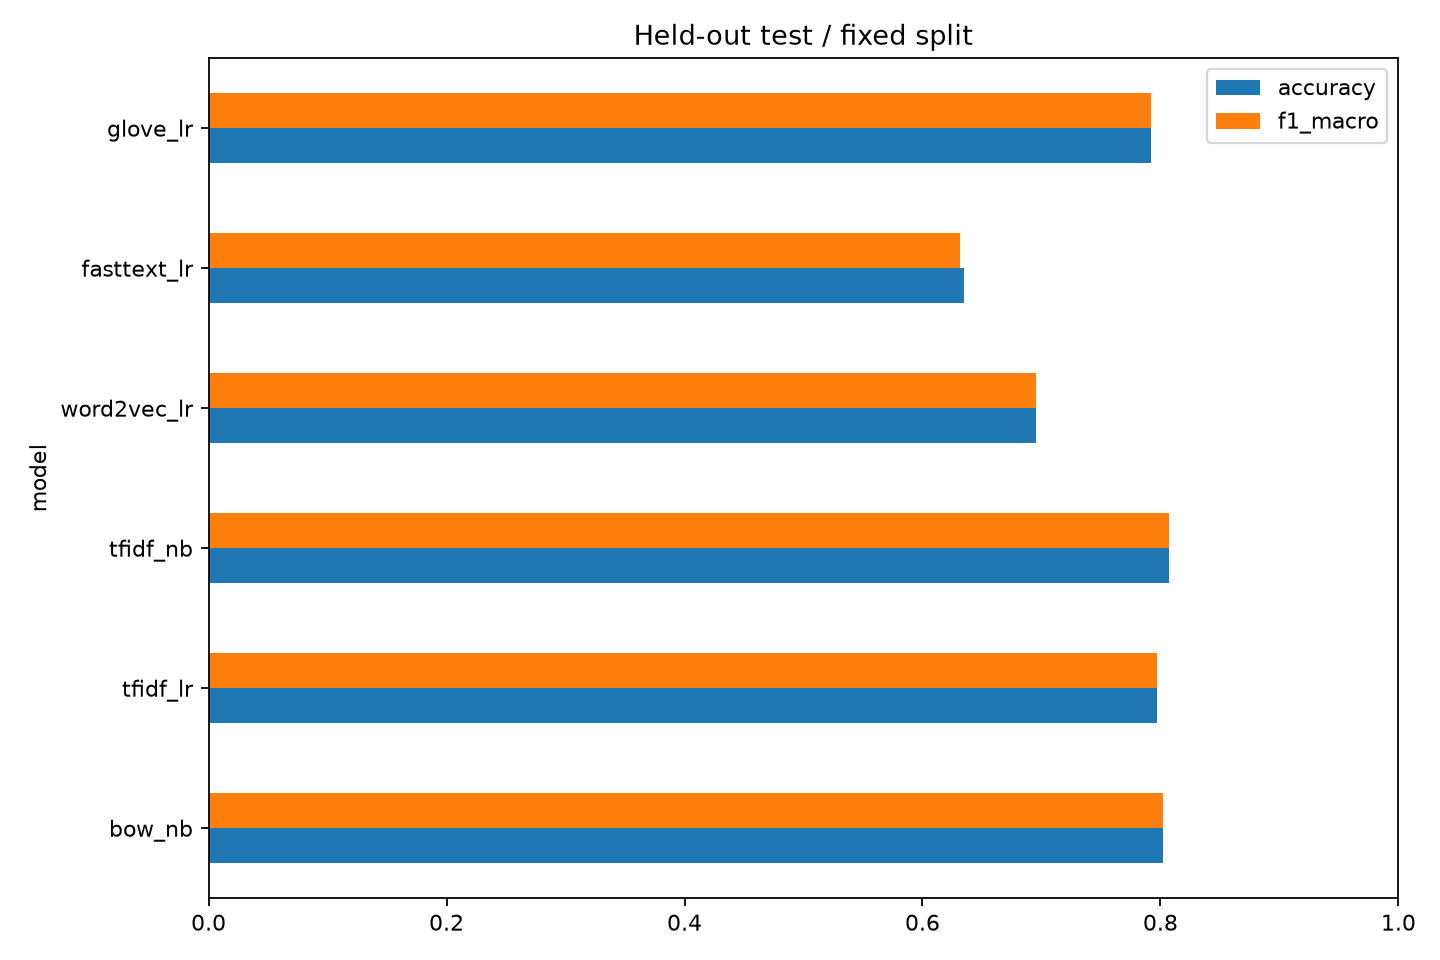

Слайдов: 10
Статус выполнения: {'classical': 'completed', 'bert': 'blocked: huggingface.co HTTP 403', 'python': '3.12.14', 'selected_model': 'bow_nb', 'selection_split': 'validation', 'presentation_slides': 10}


In [2]:
display(Markdown((ROOT / 'reports/FINAL_REPORT.md').read_text()))
display(pd.read_csv(ROOT / 'reports/all_metrics.csv'))
display(Image(filename=str(ROOT / 'reports/figures/model_comparison.png')))
from pptx import Presentation
deck = Presentation(ROOT / 'reports/presentation.pptx')
print('Слайдов:', len(deck.slides))
print('Статус выполнения:', json.loads((ROOT / 'reports/execution_status.json').read_text()))


## Выводы

Перед защитой проверьте execution_status.json: невыполненные BERT-этапы нельзя объявлять завершёнными. Покажите источник корпуса, честное разбиение, сравнение подходов, ошибку модели и работающий UI. Объясните отсутствие нейтрального класса и ограничения английского корпуса.